# Rice Leaf Disease Classification using CNN

**Project:** PRCP-1001 – Rice Leaf Disease Detection

This notebook follows the supplied project brief. The three dataset classes listed in the brief are **Leaf smut**, **Brown spot**, and **Bacterial leaf blight**. The notebook performs exploratory data analysis, image augmentation, CNN training, model comparison, evaluation, and saving the best model.

> The brief mentions 120 images (40 per class). The notebook checks the actual extracted dataset and reports the counts it finds. Do not treat sample performance as guaranteed; results depend on the data split and training environment.

In [ ]:
import os, zipfile, urllib.request, random, pathlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU devices: []


In [ ]:
# Dataset URL supplied in the project document.
ZIP_PATH = pathlib.Path("/content/RiceLeaf.zip")
EXTRACT_DIR = pathlib.Path("/content/rice_leaf_dataset")

if not EXTRACT_DIR.exists():
    print("Downloading dataset...")
    urllib.request.urlretrieve(DATASET_URL, ZIP_PATH)
    EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        zf.extractall(EXTRACT_DIR)
    print("Dataset extracted to:", EXTRACT_DIR.resolve())
else:
    print("Using existing extracted dataset:", EXTRACT_DIR.resolve())

# Automatically detect and extract nested ZIP files if they exist
for root, dirs, files in os.walk(EXTRACT_DIR):
    for file in files:
        if file.endswith(".zip"):
            nested_zip_path = pathlib.Path(root) / file
            nested_extract_dir = pathlib.Path(root) / file.replace(".zip", "")
            if not nested_extract_dir.exists():
                print(f"Extracting nested zip: {file}...")
                with zipfile.ZipFile(nested_zip_path, "r") as zf:
                    zf.extractall(nested_extract_dir)

# Find the directory whose immediate subdirectories look like class folders.
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp"}
candidate_dirs = []
for root, dirs, files in os.walk(EXTRACT_DIR):
    class_dirs = []
    for d in dirs:
        p = pathlib.Path(root) / d
        if any(f.suffix.lower() in IMAGE_EXTS for f in p.rglob("*") if f.is_file()):
            class_dirs.append(p)
    if len(class_dirs) >= 3:
        candidate_dirs.append(pathlib.Path(root))

if not candidate_dirs:
    raise FileNotFoundError(
        "Could not find a folder containing the three class folders. "
        "Check the extracted ZIP structure and set DATA_DIR manually."
    )

DATA_DIR = candidate_dirs[0]
print("Detected image folder:", DATA_DIR.resolve())
print("Class folders:", [p.name for p in DATA_DIR.iterdir() if p.is_dir()])

Using existing extracted dataset: /content/rice_leaf_dataset
Extracting nested zip: Leaf smut-20200814T055530Z-001.zip...
Extracting nested zip: Brown spot-20200814T055208Z-001.zip...
Extracting nested zip: Bacterial leaf blight-20200814T055237Z-001.zip...
Detected image folder: /content/rice_leaf_dataset/Data
Class folders: ['Bacterial leaf blight-20200814T055237Z-001', 'Leaf smut-20200814T055530Z-001', 'Brown spot-20200814T055208Z-001']


Total usable images: 119


,filename,class,width,height,mode,format
0,DSC_0385.jpg,Bacterial leaf blight-20200814T055237Z-001,3081,897,RGB,.jpg
1,DSC_0403.JPG,Bacterial leaf blight-20200814T055237Z-001,3081,897,RGB,.jpg
2,DSC_0384.JPG,Bacterial leaf blight-20200814T055237Z-001,3081,897,RGB,.jpg
3,DSC_0366.jpg,Bacterial leaf blight-20200814T055237Z-001,3081,897,RGB,.jpg
4,DSC_0367.JPG,Bacterial leaf blight-20200814T055237Z-001,3081,897,RGB,.jpg



Class counts:


,image_count
class,
Bacterial leaf blight-20200814T055237Z-001,40
Brown spot-20200814T055208Z-001,40
Leaf smut-20200814T055530Z-001,39



Image dimension summary:


,width,height
count,119.000000,119.000000
mean,2383.638655,707.739496
std,1123.528972,311.657582
min,250.000000,71.000000
25%,1074.000000,377.000000
50%,3081.000000,897.000000
75%,3081.000000,897.000000
max,3081.000000,900.000000


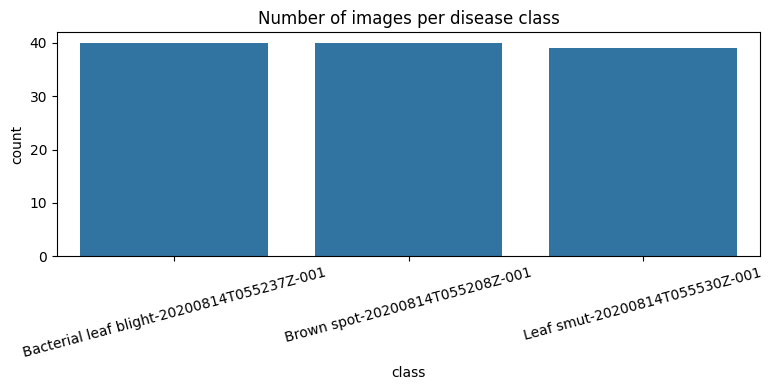

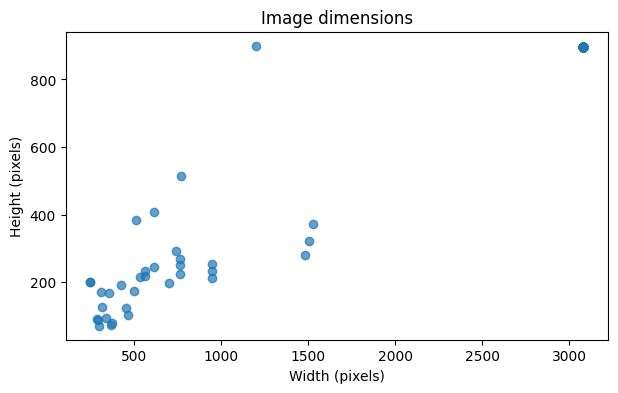

In [ ]:
class_names = sorted([p.name for p in DATA_DIR.iterdir() if p.is_dir()])
file_paths, labels, records = [], [], []

for label, class_name in enumerate(class_names):
    class_dir = DATA_DIR / class_name
    for path in class_dir.rglob("*"):
        if path.is_file() and path.suffix.lower() in IMAGE_EXTS:
            try:
                with Image.open(path) as img:
                    width, height = img.size
                    mode = img.mode
                file_paths.append(str(path))
                labels.append(label)
                records.append({
                    "filename": path.name,
                    "class": class_name,
                    "width": width,
                    "height": height,
                    "mode": mode,
                    "format": path.suffix.lower()
                })
            except Exception as e:
                print("Skipping unreadable image:", path, "|", e)

df = pd.DataFrame(records)
if len(df) == 0 or len(class_names) != 3:
    raise ValueError(f"Expected images in 3 class folders; found {len(class_names)} classes and {len(df)} images.")

print("Total usable images:", len(df))
display(df.head())
print("\nClass counts:")
display(df["class"].value_counts().rename_axis("class").to_frame("image_count"))

print("\nImage dimension summary:")
display(df[["width", "height"]].describe())

plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="class", order=class_names)
plt.title("Number of images per disease class")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.scatter(df["width"], df["height"], alpha=0.7)
plt.xlabel("Width (pixels)")
plt.ylabel("Height (pixels)")
plt.title("Image dimensions")
plt.show()

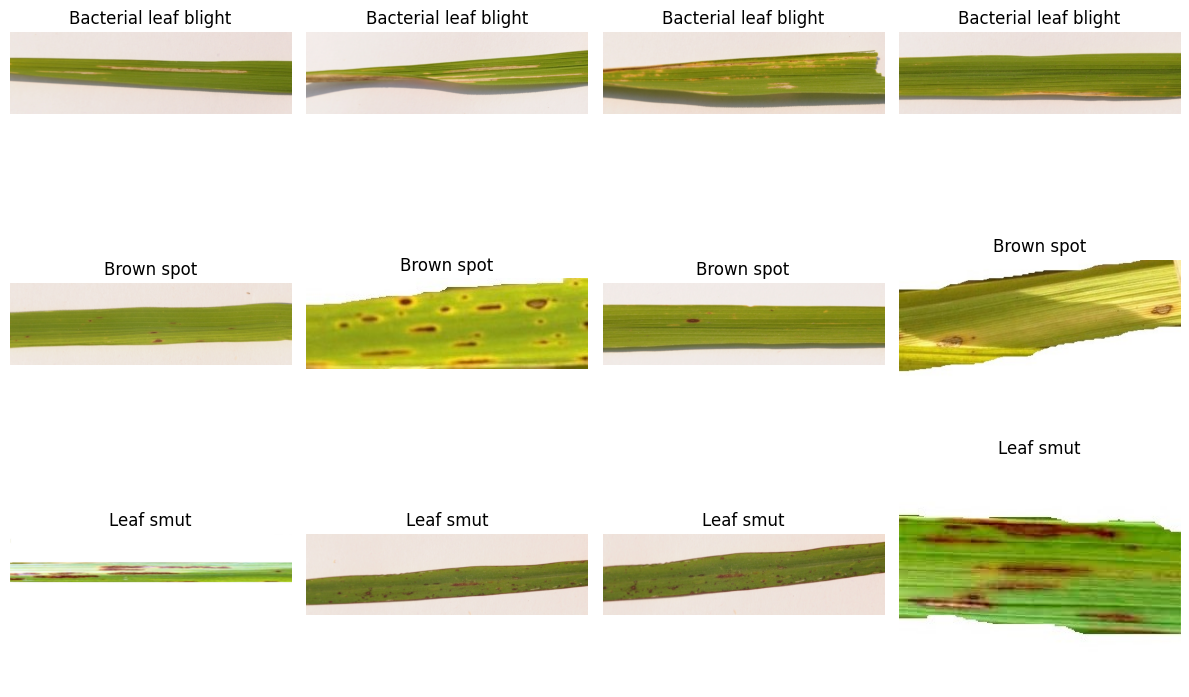

In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(12, 8))
for row, class_name in enumerate(class_names):
    samples = df[df["class"] == class_name].sample(
        min(4, (df["class"] == class_name).sum()), random_state=SEED
    )
    for col, (idx, item) in enumerate(samples.iterrows()):
        # Retrieve the complete absolute path from the file_paths list
        img_path = file_paths[idx]
        img = Image.open(img_path).convert("RGB")
        axes[row, col].imshow(img)
        axes[row, col].set_title(class_name.split('-')[0]) # Shorten the title for display
        axes[row, col].axis("off")
    for col in range(len(samples), 4):
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

In [ ]:
X = np.array(file_paths)
y = np.array(labels)

# 60% train, 20% validation, 20% test; stratified to retain class balance.
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, random_state=SEED, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

print(f"Train: {len(X_train)} | Validation: {len(X_val)} | Test: {len(X_test)}")
print("Training class counts:", dict(zip(class_names, np.bincount(y_train, minlength=3))))
print("Validation class counts:", dict(zip(class_names, np.bincount(y_val, minlength=3))))
print("Test class counts:", dict(zip(class_names, np.bincount(y_test, minlength=3))))

Train: 71 | Validation: 24 | Test: 24
Training class counts: {'Bacterial leaf blight-20200814T055237Z-001': np.int64(24), 'Brown spot-20200814T055208Z-001': np.int64(24), 'Leaf smut-20200814T055530Z-001': np.int64(23)}
Validation class counts: {'Bacterial leaf blight-20200814T055237Z-001': np.int64(8), 'Brown spot-20200814T055208Z-001': np.int64(8), 'Leaf smut-20200814T055530Z-001': np.int64(8)}
Test class counts: {'Bacterial leaf blight-20200814T055237Z-001': np.int64(8), 'Brown spot-20200814T055208Z-001': np.int64(8), 'Leaf smut-20200814T055530Z-001': np.int64(8)}


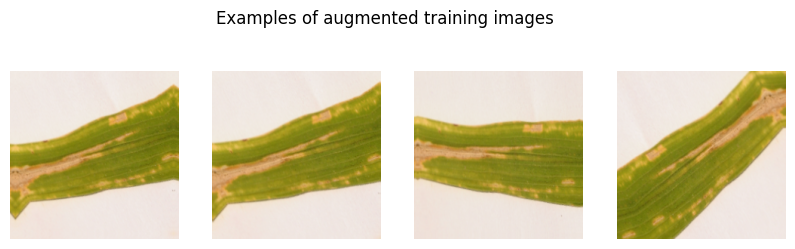

In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
AUTOTUNE = tf.data.AUTOTUNE
NUM_CLASSES = len(class_names)

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image, tf.one_hot(label, NUM_CLASSES)

def make_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_ds = make_dataset(X_train, y_train, training=True)
val_ds = make_dataset(X_val, y_val)
test_ds = make_dataset(X_test, y_test)

# Augmentation is applied only to training images.
augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10),
], name="data_augmentation")

# Visualize augmented versions of one training image.
for images, labels_batch in train_ds.take(1):
    sample = images[0:1]
    plt.figure(figsize=(10, 3))
    for i in range(4):
        aug_img = augmentation(sample, training=True)[0].numpy()
        plt.subplot(1, 4, i + 1)
        plt.imshow(np.clip(aug_img, 0, 1))
        plt.axis("off")
    plt.suptitle("Examples of augmented training images")
    plt.show()

In [ ]:
def build_basic_cnn(use_augmentation=False):
    inputs = keras.Input(shape=(*IMG_SIZE, 3))
    x = inputs
    if use_augmentation:
        x = augmentation(x)
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Dropout(0.30)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.30)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    model = keras.Model(inputs, outputs)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

basic_cnn = build_basic_cnn(use_augmentation=False)
basic_cnn.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,147 (430.26 KB)

 Trainable params: 110,147 (430.26 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6)
]

EPOCHS = 30
history_basic = basic_cnn.fit(
    train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks
)

Epoch 1/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 12s 2s/step - accuracy: 0.2958 - loss: 1.1185 - val_accuracy: 0.3750 - val_loss: 1.0937 - learning_rate: 0.0010
Epoch 2/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 9s 2s/step - accuracy: 0.3099 - loss: 1.1069 - val_accuracy: 0.3750 - val_loss: 1.0946 - learning_rate: 0.0010
Epoch 3/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 11s 2s/step - accuracy: 0.3521 - loss: 1.1019 - val_accuracy: 0.4583 - val_loss: 1.0930 - learning_rate: 0.0010
Epoch 4/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step - accuracy: 0.3662 - loss: 1.0986 - val_accuracy: 0.4583 - val_loss: 1.0886 - learning_rate: 0.0010
Epoch 5/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step - accuracy: 0.3803 - loss: 1.0920 - val_accuracy: 0.4167 - val_loss: 1.0836 - learning_rate: 0.0010
Epoch 6/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 12s 2s/step - accuracy: 0.3803 - loss: 1.0822 - val_accuracy: 0.3750 - val_loss: 1.0762 - learning_rate: 0.0010
Epoch 7/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step - accuracy: 0.3521 - loss: 1.0766 - val_accuracy: 0.3750 - val_los

In [ ]:
aug_cnn = build_basic_cnn(use_augmentation=True)
history_aug = aug_cnn.fit(
    train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks
)

Epoch 1/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 13s 2s/step - accuracy: 0.3239 - loss: 1.1090 - val_accuracy: 0.3333 - val_loss: 1.0972 - learning_rate: 0.0010
Epoch 2/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step - accuracy: 0.2535 - loss: 1.1073 - val_accuracy: 0.3333 - val_loss: 1.0964 - learning_rate: 0.0010
Epoch 3/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 11s 2s/step - accuracy: 0.3099 - loss: 1.1067 - val_accuracy: 0.3333 - val_loss: 1.0961 - learning_rate: 0.0010
Epoch 4/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 9s 2s/step - accuracy: 0.3662 - loss: 1.0942 - val_accuracy: 0.3333 - val_loss: 1.0956 - learning_rate: 5.0000e-04
Epoch 5/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 12s 2s/step - accuracy: 0.3099 - loss: 1.0933 - val_accuracy: 0.3333 - val_loss: 1.0951 - learning_rate: 5.0000e-04
Epoch 6/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 18s 2s/step - accuracy: 0.3239 - loss: 1.0973 - val_accuracy: 0.3750 - val_loss: 1.0943 - learning_rate: 5.0000e-04
Epoch 7/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step - accuracy: 0.3803 - loss: 1.0830 - val_accuracy: 0.3

In [ ]:
# Transfer learning can be useful when the project dataset is small.
# The preprocessing layer converts [0,1] image values to the range expected by MobileNetV2.
base_model = keras.applications.MobileNetV2(
    input_shape=(*IMG_SIZE, 3), include_top=False, weights="imagenet"
)
base_model.trainable = False

inputs = keras.Input(shape=(*IMG_SIZE, 3))
x = augmentation(inputs)
x = layers.Rescaling(2.0, offset=-1.0)(x)  # [0,1] -> [-1,1]
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.30)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
transfer_model = keras.Model(inputs, outputs)

transfer_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
history_transfer = transfer_model.fit(
    train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 15s 2s/step - accuracy: 0.3944 - loss: 1.1623 - val_accuracy: 0.6667 - val_loss: 0.8129 - learning_rate: 0.0010
Epoch 2/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 5s 881ms/step - accuracy: 0.6338 - loss: 0.9326 - val_accuracy: 0.6667 - val_loss: 0.7064 - learning_rate: 0.0010
Epoch 3/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 7s 1s/step - accuracy: 0.7606 - loss: 0.7465 - val_accuracy: 0.7917 - val_loss: 0.5349 - learning_rate: 0.0010
Epoch 4/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 9s 898ms/step - accuracy: 0.7465 - loss: 0.6424 - val_accuracy: 0.8750 - val_loss: 0.4181 - learning_rate: 0.0010
Epoch 5/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 6s 935ms/step - accuracy: 0.7042 - loss: 0.5705 - val_accuracy: 1.0000 - val_loss: 0.3501 - learning_rate: 0.0010
Epoch 6/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 4s 793ms/step - accuracy: 0.8451 - loss: 0.4176 - val_accuracy: 0.9167 - val_loss: 0.3316 - learning_rate: 0.0010
Epoch 7/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - accurac

,Model,Validation loss,Validation accuracy
2,MobileNetV2 Transfer Learning,0.091558,1.000000
0,Basic CNN,0.822468,0.625000
1,CNN + Augmentation,1.097237,0.333333


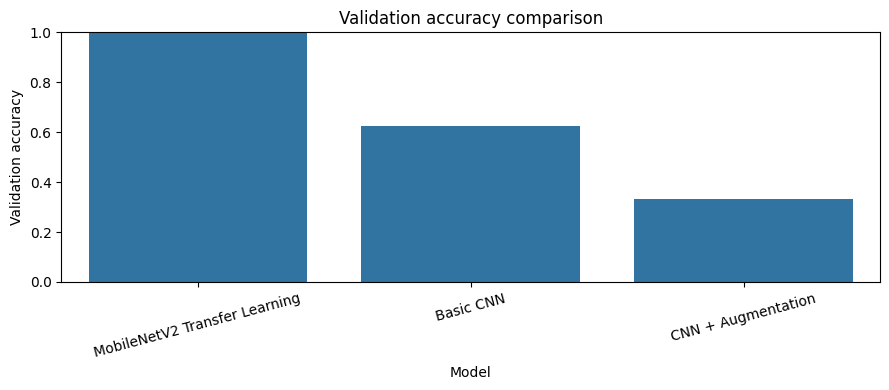

Best model based on validation accuracy: MobileNetV2 Transfer Learning


In [ ]:
models = {
    "Basic CNN": basic_cnn,
    "CNN + Augmentation": aug_cnn,
    "MobileNetV2 Transfer Learning": transfer_model
}

comparison = []
for name, model in models.items():
    loss, accuracy = model.evaluate(val_ds, verbose=0)
    comparison.append({"Model": name, "Validation loss": loss, "Validation accuracy": accuracy})

comparison_df = pd.DataFrame(comparison).sort_values("Validation accuracy", ascending=False)
display(comparison_df)

plt.figure(figsize=(9, 4))
sns.barplot(data=comparison_df, x="Model", y="Validation accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.title("Validation accuracy comparison")
plt.tight_layout()
plt.show()

best_name = comparison_df.iloc[0]["Model"]
best_model = models[best_name]
print("Best model based on validation accuracy:", best_name)

Test loss: 0.4347
Test accuracy: 0.8750
                                            precision    recall  f1-score   support

Bacterial leaf blight-20200814T055237Z-001       1.00      0.88      0.93         8
           Brown spot-20200814T055208Z-001       0.73      1.00      0.84         8
            Leaf smut-20200814T055530Z-001       1.00      0.75      0.86         8

                                  accuracy                           0.88        24
                                 macro avg       0.91      0.88      0.88        24
                              weighted avg       0.91      0.88      0.88        24



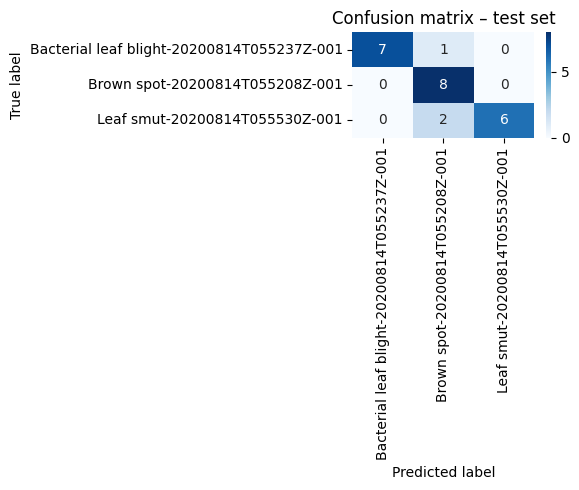

In [ ]:
test_loss, test_accuracy = best_model.evaluate(test_ds, verbose=0)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

y_true = []
y_pred = []
for images, one_hot_labels in test_ds:
    probabilities = best_model.predict(images, verbose=0)
    y_pred.extend(np.argmax(probabilities, axis=1))
    y_true.extend(np.argmax(one_hot_labels.numpy(), axis=1))

print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Confusion matrix – test set")
plt.tight_layout()
plt.show()

In [ ]:
def predict_rice_leaf(image_path, model=best_model):
    img = keras.utils.load_img(image_path, target_size=IMG_SIZE)
    arr = keras.utils.img_to_array(img).astype("float32") / 255.0
    arr = np.expand_dims(arr, axis=0)
    probabilities = model.predict(arr, verbose=0)[0]
    predicted_index = int(np.argmax(probabilities))
    print("Predicted disease:", class_names[predicted_index])
    print("Confidence:", f"{probabilities[predicted_index] * 100:.2f}%")
    return pd.DataFrame({
        "Disease": class_names,
        "Probability": probabilities
    }).sort_values("Probability", ascending=False)

# Example:
predict_rice_leaf("/content/leaf-smut-8-10-4.jpg")

Predicted disease: Leaf smut-20200814T055530Z-001
Confidence: 86.93%


,Disease,Probability
2,Leaf smut-20200814T055530Z-001,0.869301
1,Brown spot-20200814T055208Z-001,0.119331
0,Bacterial leaf blight-20200814T055237Z-001,0.011368


In [ ]:
best_model.save("rice_leaf_disease_cnn.keras")
with open("rice_leaf_class_names.json", "w") as f:
    json.dump(class_names, f)

print("Saved model: rice_leaf_disease_cnn.keras")
print("Saved labels: rice_leaf_class_names.json")

Saved model: rice_leaf_disease_cnn.keras
Saved labels: rice_leaf_class_names.json


## 15. Project report notes – challenges and techniques

Use the actual outputs from this notebook when writing your final report.

| Challenge | Technique used | Reason |
|---|---|---|
| Small dataset (brief states 120 images) | Data augmentation | Creates varied training examples and may reduce overfitting |
| Different image dimensions | Resize to 224 × 224 | Gives the CNN a consistent input shape |
| Risk of class imbalance | Stratified train/validation/test split | Preserves class proportions in each split |
| Overfitting risk | Dropout and early stopping | Helps limit overfitting and stops training when validation loss stops improving |
| Comparing approaches | Basic CNN, augmented CNN, MobileNetV2 | Allows comparison using the same validation data |

### Conclusion template

After running the notebook, state which model had the highest validation accuracy, then report its test accuracy and class-wise precision/recall/F1-score. Recommend the model with the strongest test performance and balanced class-wise results, not validation accuracy alone. Because the dataset is small, further testing on more real-world field images is recommended before production use.

**Important:** The supplied brief's problem statement mentions “leaf blast”, but its dataset class list specifies **Leaf smut**, **Brown spot**, and **Bacterial leaf blight**. This notebook uses the three class folders found in the dataset and prints their names. Confirm the class naming with your project supervisor before final submission.